# Lesson 33: Galvanostatic Techniques I: Chronopotentiometry and the Sand Equation
Everything so far has controlled the potential and measured the current. We can flip that: fix the current and watch what the potential has to do to sustain it. Conceptually this is a redox titration in which you set the delivery rate yourself.

Today's topics:
- The constant current waveform and characteristic time
- The Sand equation and the expected potential-time response
- Checks for reversibility, and reversing the current

**Reference:**
- Sections 8.1 to 8.4 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets
from IPython.display import Image

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE      # constants and the two-panel figure size
echem.use_style()                       # course-wide graph formatting

N_ELECTRONS = 1
E_QUARTER = 0.0                 # V, the potential at t = tau/4

# 1. Waveforms

We initiated discussions on experiments using the simplest possible *potentiostatic* experiment - a potential step, or [chronoamperometry](L16-Chronoamperometry-I.ipynb). We can increase the complexity of the experiment, and the information that can be extracted, by adjusting the experiment. For example, a sequential series of potentiostatic measurements can be used to perform *voltammetric* analysis on a system. The same situation exists for controlled current techniques.

We will start today with the same simple starting point, then move much more quickly through more complex situations. The simplest possible experiment is once again the application of a single constant current. This measurement technique is referred to as *chronopotentiometry* (voltage-as-function-of-time), and may be referred to as a *galvanostatic* measurement.

Our discussions will assume our generic redox reaction:

 $ \large O + e^- \rightleftharpoons R$ 

With the starting conditions of:

 $\large C_O^*/C_T = 1 $ 

 $\large C_R^*/C_T = 0 $ 

And the relevant boundary conditions for a system described by *semi-infinite diffusion* assumptions.

Text(0.5, 0.5, '?')

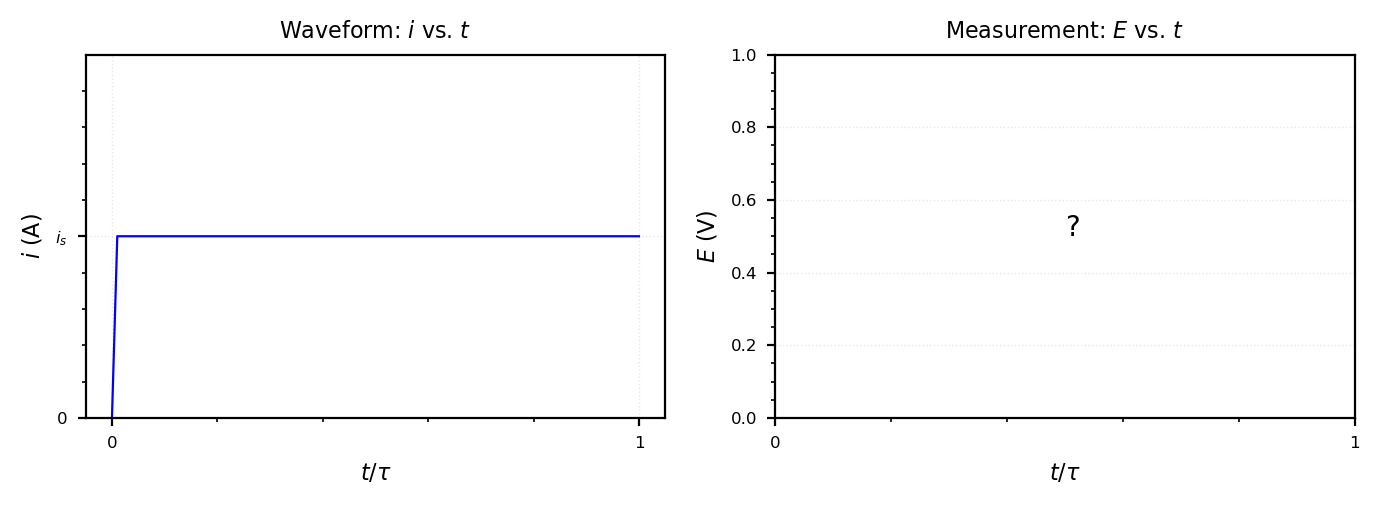

In [2]:
# The galvanostatic experiment: set the current, measure the potential.
t = np.linspace(0, 1, 100)
current = np.ones(100)
current[0] = 0.

fig = plt.figure(figsize=WIDE)
ax1 = plt.subplot(121)
ax2 = plt.subplot(122)

for ax in [ax1, ax2]:
    ax.set_xticks([0, 1.0])
    ax.set_xticklabels([0, 1])

ax1.set_title(r'Waveform: $i$ vs. $t$')
ax1.set_yticks([0, 1.0])
ax1.set_yticklabels([r"0", r"$i_s$"])
ax1.set_ylim(0, 2)
ax1.set_xlabel(r'$t/\tau$')
ax1.set_ylabel(r'$i$ (A)')
ax1.plot(t, current, 'blue')

ax2.set_title(r'Measurement: $E$ vs. $t$')
ax2.set_xlabel(r'$t/\tau$')
ax2.set_ylabel(r'$E$ (V)')
ax2.annotate('?', (0.5, 0.5))

## Constant Current Waveform:

The specific variables representing the parameters will vary from instrument to instrument, but the parameters are:
- $\large i_i$ : Initial current (not shown). Generally selected to be zero such that the system starts at rest. 
- $\large i_s$ : Step current. Magnitude of current that will be applied to the system.
- $\large t$ : Time that the current step is applied. Data above is normalized by $\tau$ 
- $\large \tau$ : Characteristic time of the redox couple being studied.

## Characteristic Time: A Redox Titration

The *characteristic time* for a redox system to respond is a new concept for us. Conceptually, it is easiest to understand this term by thinking of the constant current experiment as a titration (which it is - a redox titration). You pass electrons into your system at a constant rate. The resulting redox reaction induces continual growth of the diffusion layer at the electrode surface: concentrations of the reactant decrease from their bulk concentration values to zero, while those of products increase from their bulk concentration to 100%. The only way the system can respond after this is by expanding the diffusion layer further into solution. This results in a sudden spike in voltage required to maintain $i_s$ . This is the same as doing an acid-base titration, except it is now an electron-transfer reaction rather than a proton transfer reaction.

<div class="alert alert-block alert-success">
<b>Characteristic time ( $\tau$ ):</b> The time at which the redox active species can no longer diffuse to the electrode surface at a rate that matches the constant current.
</div>

### Sand Equation

By setting up suitable boundary conditions and performing the necessary Laplace transforms, one can derive mathematical descriptions for the concentration of **O** and **R** as a function of distance from the electrode ( $x$ ):

$
\large C_O(x,t) = C_O^* - \frac{i}{n F A D_O} \left( 2\sqrt{\frac{D_Ot}{\pi}} \cdot e^{\frac{-x^2}{4D_Ot}} -x \cdot erfc\left[ \frac{x}{2\sqrt{D_Ot}} \right]\right)
$

$
\large C_R(x,t) = C_R^* + \frac{i}{n F A D_R} \left( 2\sqrt{\frac{D_Rt}{\pi}} \cdot e^{\frac{-x^2}{4D_Rt}} -x \cdot erfc\left[ \frac{x}{2\sqrt{D_Rt}} \right]\right)
$

These equations can be readily visualized here:

In [3]:
@interact(t=widgets.FloatText(value=3., description=r'$t$ /s'),
          applied_current=widgets.FloatText(value=0.01, description=r'$i$ /A'),
          n=widgets.BoundedIntText(value=1, min=1, max=6, description=r'$n$'),
          area=widgets.FloatText(value=1, step=1, description=r'$A$ /cm$^2$'),
          diff_o=widgets.FloatText(value=1e-5, step=1e-6,
                                   description=r'$D_O$ /cm$^2$s$^{-1}$'),
          conc_o=widgets.FloatText(value=1e-4, step=1e-5,
                                   description=r'$C_O^*$ /mol cm$^{-3}$'))
def plot_chronopotentiometry_profile(t, applied_current, n, area, diff_o, conc_o):
    '''Titrating the surface at a fixed rate: the profile sags steadily.

    Compare with a potential step, where the surface concentration drops to its
    new value instantly.  Here it falls gradually, and tau is the moment it
    reaches zero.
    '''
    if min(t, applied_current, area, diff_o, conc_o) <= 0:
        print('Every setting must be greater than zero.')
        return

    tau = echem.sand_time(applied_current, conc_o, diff_o, area, n)
    x = np.linspace(0, echem.diffusion_layer_thickness(diff_o, t, multiplier=4), 100)
    profile = echem.chronopotentiometry_profile(x, applied_current, t, diff_o,
                                                conc_o, area, n)

    fig = plt.figure()
    ax = plt.subplot()
    ax.set_xlabel(r'$\frac{x}{2\sqrt{D_O\tau}}$')
    ax.set_ylabel(r'$\frac{C_j}{C_j^*}$', rotation=0)
    ax.plot(x/(2*np.sqrt(diff_o*tau)), profile, 'blue',
            label=rf'$t/\tau$ = {t/tau:.2f}')
    ax.annotate(rf'$\tau$ = {tau:.2f} s', (0.7, 0.1), xycoords='axes fraction', fontsize=6)
    ax.legend(fontsize=6)

interactive(children=(FloatText(value=3.0, description='$t$ /s'), FloatText(value=0.01, description='$i$ /A'),…

We can acquire some insights into specific expected behavior by further simplifying the equation. The requirement for the characteristic time, $\tau$ , is that the concentration of the reactant species at the surface hits its limit of 0. If we limit our focus to only where $x=0$ , two of the terms in the equations above become irrelevant: the exponential term becomes one, while the $x\cdot$ erfc term becomes 0. Therefore:

$
\large C_O(x=0,t) = C_O^* - \frac{2i\sqrt{t}}{n F A \sqrt{D_O\pi}}
$

We can then consider ONLY the situation where we are at the characteristic time:

$
\large C_O(x=0, \tau)= C_O^* - \frac{2i\sqrt{\tau}}{n F A \sqrt{D_O\pi}}
$

If we then rearrange this equation such that all parameters expected to be constant are on one side, we obtain:

$
\large \frac{i \sqrt{\tau}}{C_O^*} = \frac{n F A \sqrt{D_O \pi}}{2}
$

This equation is known as the **Sand Equation** and it gives us several insights into the expected behavior of the system:
- the equation contains four variables that are constants ( $n, A, D_O, C_O^*$ ) for a reaction system. We therefore have a situation with only two variables that are altered during an experiment: we can measure $\tau$ as a function of $i$ and determine any of the four constants...assuming we have knowledge of the other three.
- the left term is referred to as the *transition time constant* for the system. The Sand Equation makes it clear that this is a constant value for a given reaction system. The characteristic time is dependent on both $C_O^*$ and $i$ ; increases or decreases in either of these terms will result in corresponding changes to $\tau$ .

This equation can be recast in a slightly different way, which allows us to predict $\tau$ :

$
\large \tau = \pi D_O \left( \frac{nFAC_O^*}{2i} \right)^2 
$

# 2. Experimental Response

The expected $E$ - $t$ response of the system is straightforward to predict using the equations we developed above. The step immediately prior to the Sand equation provides a means to calculate concentration at $x=0$ at any time; combination of this equation with the Sand equation allows the concentrations of the oxidized and reduced species to be determined at arbitrary times, as a function of starting concentration of one species:

$
\large C_O(0,t) = C_O^*\left(1 - \sqrt{\frac{t}\tau{}} \right)
$

$
\large C_R(0,t) = \xi C_O^*\left(\sqrt{\frac{t}\tau{}} \right)
$

Where $\xi = \sqrt{D_O/D_R}$ . These two concentrations can then be simply plugged into the Nernst equation to yield:

$
\large E(t) = E_{\tau/4} + \frac{RT}{nF} ln \left( \frac{\sqrt{\tau} - \sqrt{t}}{ \sqrt{t} } \right)
$

Where:

$
\large E_{\tau/4} = E^{0'} + \frac{RT}{nF} ln \left( \sqrt{\frac{D_R}{D_O}} \right)
$

This new term, $E_{\tau/4}$ is named the *quarter-wave potential*. This term resides in the position expected for $E_{1/2}$ for voltammetric experiments, which tells us that this will be the inflection point of our $E-t$ curve; the $\tau/4$ naming reflects the fact that this position now occurs at an experimental time of $t = \tau/4$ . Assuming that $D_O = D_R$ , we can see the generic behavior:

Remember: all of this handling assumes a fully reversible electrochemical reaction.

In [4]:
T_OVER_TAU = np.linspace(0.001, 0.999, 200)

@interact(e_quarter=widgets.FloatSlider(value=0., min=-0.1, max=0.1, step=0.01,
                                        description=r'$E_{\tau/4}$ V'),
          n=widgets.BoundedIntText(value=1, min=1, max=6, description=r'$n$'))
def plot_chronopotentiogram(e_quarter, n):
    '''The E-t curve is the Nernst equation again, swept by the titration.

    The two dotted horizontal lines are separated by 47.9/n mV, the reversibility
    test discussed above.  echem.CHRONOPOT_REVERSIBILITY_SPACING holds that number.
    '''
    fig = plt.figure()
    ax = plt.subplot()
    ax.set_xlabel(r'$\frac{t}{\tau}$')
    ax.set_xlim(0, 1)
    ax.set_ylabel(r'$E$ /V', rotation=0)
    ax.set_ylim(-0.2, 0.1)

    ax.plot(T_OVER_TAU, echem.chronopotentiogram(T_OVER_TAU, e_quarter, n), 'blue')
    spacing = echem.CHRONOPOT_REVERSIBILITY_SPACING/n
    ax.axhline(e_quarter, linestyle=':')
    ax.axhline(e_quarter - spacing, linestyle=':')
    ax.axvline(0.25, linestyle=':')
    ax.axvline(0.75, linestyle=':')
    ax.set_title(rf'$E_{{\tau/4}} - E_{{3\tau/4}}$ = {1000*spacing:.1f} mV', fontsize=8)

interactive(children=(FloatSlider(value=0.0, description='$E_{\\tau/4}$ V', max=0.1, min=-0.1, step=0.01), Bou…

## Checks for Reversibility 
The form of the Nernst equation provided above gives us two direct methods that we can use to check our data for electrochemical reversibility.

For the first method, we can simply choose two time points along the curve and compare the voltages seen at them. It is logical to use $E_{\tau/4}$ as one point, because it has physical meaning. The second point can be somewhat arbitrarily selected:

In [5]:
@interact(t1_tau=widgets.FloatSlider(value=0.25, min=0.05, max=0.99, step=0.01,
                                     description=r'$t_1/\tau$'),
          t2_tau=widgets.FloatSlider(value=0.75, min=0.05, max=0.99, step=0.01,
                                     description=r'$t_2/\tau$'))
def report_reversibility_spacing(t1_tau, t2_tau):
    '''Pick any two times and the spacing between them is fixed for a reversible couple.'''
    e_shift = (echem.chronopotentiogram(t1_tau, n=N_ELECTRONS)
               - echem.chronopotentiogram(t2_tau, n=N_ELECTRONS))
    print(f'Spacing expected: {1000*e_shift:.1f} mV')

interactive(children=(FloatSlider(value=0.25, description='$t_1/\\tau$', max=0.99, min=0.05, step=0.01), Float…

It is common to select the second time to be 0.75 $t/\tau$ , which provides a sufficient breadth of time to minimize inaccuracies while remaining pinned to the general anchor point. 

The second approach is to create a plot that linearizes the entire dataset. Inspection of the Nernst equation above tells us that we should obtain linearity in a plot of $E(t)$ vs $ln\left(\frac{\sqrt{\tau} - \sqrt{t}}{\sqrt{t}}\right)$ . 

<div class="alert alert-block alert-info">
 <b>Activity</b>: Carefully articulate to your neighbor what happens to $E$ as $t$ increases to, and beyond, $\tau$ ?
</div>

# 3. Practical Considerations

Galvanostatic techniques should be viewed as being complementary to voltammetric and amperometric ones. They have strengths and weaknesses that differ from the techniques we discussed earlier.

Some key strengths:
- Equipment is simpler (and therefore cheaper)
- Mathematics is generally simpler because reactions take place at a constant rate at an interface; diffusion occurs as a result, rather than as a driving force.
- Precise control over charge passed is facilitated, which enables accurate measurement of concentrations.

Some key weaknesses:
- Charging currents are a function of voltage; the more complex changes in voltage that arise in this technique make contributions from charging current non-trivial
- Redox transitions tend to occur across a larger voltage range, which makes it more difficult to analyze sequential reactions or reactions from multiple species in solution.

Contributions from current used to charge the electrical double layer ( $i_{dl}$ ) are particularly problematic. This current is required to establish the charged interface, which establishes the desired electrochemical potential. We have previously seen a version for a potential step waveform, where the current is dependent on solution resistance and the time-constant of the electrochemical cell used:

$
\large i_{dl} = \frac{E}{R_s} e^{\frac{-t}{R_s C_{dl}}}
$

We have also seen it for a potential sweep experiment, where the sweep rate and double layer capacitance are important:

$
\large i_{dl} = \nu C_{dl}
$

In chronopotentiometry, $E$ changes in a non-linear fashion:

In [6]:
T_OVER_TAU = np.linspace(0.001, 0.999, 199)
E_QUARTER = 0.0

@interact(t=widgets.FloatSlider(value=0.5, min=0.001, max=0.999, step=0.01,
                                description=r'$t/{\tau}$'))
def plot_effective_scan_rate(t):
    '''A galvanostatic experiment sweeps the potential for you, but not linearly.

    The right hand panel is the effective scan rate.  It is slowest near
    t = tau/2 and runs away as the transition time approaches.
    '''
    potential = echem.chronopotentiogram(T_OVER_TAU, E_QUARTER, N_ELECTRONS)

    fig = plt.figure(figsize=WIDE)
    ax = plt.subplot(121)
    ax2 = plt.subplot(122, sharex=ax)

    ax.set_xlabel(r'$\frac{t}{\tau}$')
    ax.set_xlim(0, 1)
    ax.set_ylabel(r'$E$ /V')
    ax.set_ylim(-0.2, 0.1)
    ax.plot(T_OVER_TAU, potential, 'blue')
    ax.axvline(t, linestyle=':')

    # np.gradient needs the x values, or it returns the change PER SAMPLE
    # rather than per unit of t/tau.
    scan_rate = np.gradient(potential, T_OVER_TAU)
    ax2.plot(T_OVER_TAU, scan_rate, 'blue')
    ax2.set_xlabel(r'$\frac{t}{\tau}$')
    ax2.set_ylabel(r'$\frac{\delta E}{\delta (t/\tau)}$  /V')
    ax2.axvline(t, linestyle=':')
    ax2.set_ylim(-1.0, 0)

    idx = echem.nearest_index(T_OVER_TAU, t)
    ax2.annotate(rf'{scan_rate[idx]:.3f} V per unit $t/\tau$',
                 (0.35, 0.2), xycoords='axes fraction', fontsize=6)

interactive(children=(FloatSlider(value=0.5, description='$t/{\\tau}$', max=0.999, min=0.001, step=0.01), Outp…

# 4. Introducing Electrochemical Irreversibility

The equations surrounding galvanostatic measurements can be modified in exactly the same way as we did with voltammetric methods. For irreversibility, this means that $C_j(x=0,t)$ is not satisfied by the Nernstian equilibrium equation; we need to introduce some form of kinetic equation. Using the equations derived from the Butler-Volmer approach, we obtain:

$
\large E = E^{0'} + \frac{RT}{\alpha F} ln \left( \frac{2k^0}{\sqrt{\pi D_j}} \right) + \frac{RT}{\alpha F} ln (\sqrt{\tau} - \sqrt{t})
$

The equation is broken up into three portions to highlight the structure expected:
- The curve is still based around the formal potential.
- the term containing $k^0$ is **time-independent** and has an $\alpha$ pre-factor. It therefore only serves to shift the curve on the $E$ axis, as a function $k^0$ and $\alpha$ .
- the term containing $\tau$ is time dependent. The shape of the curve is therefore affected by $\alpha$ .

Remember that the Sand equation was defined assuming electrochemical reversibility - it therefore **cannot** be used to calculate $\tau$ in this situation.

In [7]:
# Irreversible chronopotentiometry: kinetics, not thermodynamics, set the potential.
DIFF = 1e-5                                     # cm2/s, a standard aqueous value
T_OVER_TAU_IRR = np.linspace(0.001, 0.999, 100)
TAU = 1.0                                       # s, the transition time assumed for these curves


def chronopotentiometry_irreversible(e_formal, k0, alpha):
    '''E(t) when the surface concentration is set by kinetics rather than by Nernst.'''
    return (e_formal
            + np.log(2*k0*np.sqrt(TAU)/np.sqrt(np.pi*DIFF))/(alpha*f)
            + np.log(1 - np.sqrt(T_OVER_TAU_IRR))/(alpha*f))


@interact(e_formals=widgets.Text('0, 0, 0', description=r'$E^{0}$ /V'),
          k_0s=widgets.Text('0.01, 0.001, 0.0001', description=r'$k^0$ /cm s$^{-1}$'),
          alphas=widgets.Text('0.5, 0.5, 0.5', description=r'$\alpha$'))
def plot_irreversible_chronopotentiometry(e_formals, k_0s, alphas):
    '''Three curves at once.  Slower kinetics push the whole curve to more extreme E.'''
    try:
        e_values = echem.parse_numbers(e_formals, name='E0')
        k_values = echem.parse_numbers(k_0s, expected=e_values.size, name='k0')
        a_values = echem.parse_numbers(alphas, expected=e_values.size, name='alpha')
    except ValueError as problem:
        print(problem)
        return

    fig = plt.figure()
    ax = plt.subplot()
    ax.set_xlabel(r'$\frac{t}{\tau}$')
    ax.set_xlim(0, 1)
    ax.set_ylabel(r'$E$ /V')
    ax.set_ylim(-0.5, 0.1)

    for e_formal, k0, alpha in zip(e_values, k_values, a_values):
        ax.plot(T_OVER_TAU_IRR, chronopotentiometry_irreversible(e_formal, k0, alpha),
                label=f'E: {e_formal:g}, k0: {k0:g}, alpha: {alpha:g}')
    ax.legend(fontsize=6, loc=3)

interactive(children=(Text(value='0, 0, 0', description='$E^{0}$ /V'), Text(value='0.01, 0.001, 0.0001', descr…

<div class="alert alert-block alert-info">
 <b>Activity</b> Consider the equations and figure above. Quantitatively, how would one expect the curve to shift as a function of $\alpha$ and $k^0$ ?
</div>

# 5. Current Reversal or Cyclic Chronopotentiometry

Under semi-infinite diffusion conditions the reversal of current (ie, changing from a reduction to an oxidation current, or an oxidation to a reduction) would result in our operating on the diffusion layer rather than the bulk system. This, once again, echoes the voltage-controlled experiments. The waveform is readily generated, but the outcome may be a surprise:

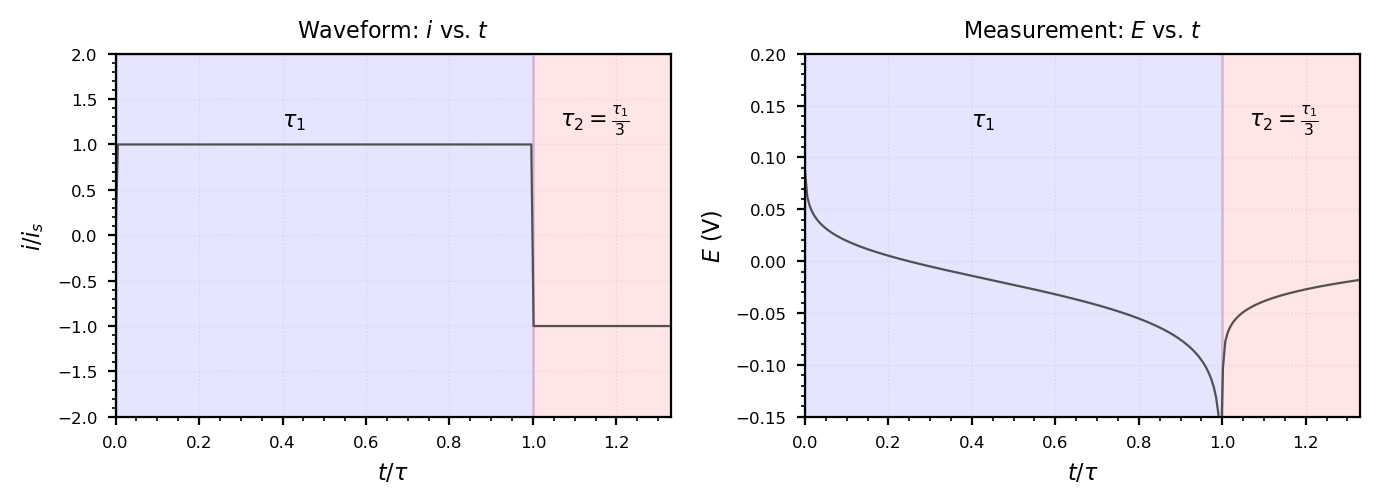

In [8]:
# Current reversal.  Reversing the current works on the diffusion layer that the
# first half of the experiment built, not on bulk solution, which is why the
# second transition time is only one third of the first.
#
# NOTE: the reverse branch below is a SCHEMATIC.  Negating the forward E-t curve
# gives the right general shape, but it is not the Berzins-Delahay current
# reversal response, so tau_2 = tau_1/3 cannot be recovered analytically from it.
T_OVER_TAU = np.linspace(0.001, 0.999, 180)
t = np.linspace(0, 1.33, 240)
current = np.ones(240)
current[0] = 0.
current[180:] = -current[180:]

fig = plt.figure(figsize=WIDE)
ax1 = plt.subplot(121)
ax2 = plt.subplot(122, sharex=ax1)

for ax in [ax1, ax2]:
    ax.set_xlim(0, 1.33)
    ax.annotate(r'$\tau_1$', (0.3, 0.8), xycoords='axes fraction', fontsize=8)
    ax.annotate(r'$\tau_2 = \frac{\tau_1}{3}$', (0.8, 0.8),
                xycoords='axes fraction', fontsize=8)
    ax.fill_between([0, 1], -2, 2, color='blue', alpha=0.1)
    ax.fill_between([1, 1.333], -2, 2, color='red', alpha=0.1)

ax1.set_title(r'Waveform: $i$ vs. $t$')
ax1.set_ylim(-2, 2)
ax1.set_xlabel(r'$t/\tau$')
ax1.set_ylabel(r'$i/i_s$')
ax1.plot(t, current)

forward = echem.chronopotentiogram(T_OVER_TAU, E_QUARTER, N_ELECTRONS)
reverse = -echem.chronopotentiogram(T_OVER_TAU/3, E_QUARTER, N_ELECTRONS)
ax2.set_title(r'Measurement: $E$ vs. $t$')
ax2.set_xlabel(r'$t/\tau$')
ax2.set_ylabel(r'$E$ (V)')
ax2.set_ylim(-0.15, 0.2)
ax2.plot(t, np.hstack([forward, reverse])[:t.size])

fig.savefig('../Workspace/current-reversal.png')

<div class="alert alert-block alert-info">
 <b>Activity</b> Discuss with your neighbor why $\tau_2 = \frac{\tau_1}{3}$ .
</div>